## Импорт библиотек и настройки

In [1]:
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from IPython.display import display
from catboost import CatBoostClassifier, Pool
from catboost.utils import get_gpu_device_count
from sksurv.util import Surv
from sksurv.metrics import brier_score
from sksurv.nonparametric import kaplan_meier_estimator

ROOT = Path(r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring")
DATA_PATH = ROOT / "data/processed/ml_survival_dataset.parquet"
SPLIT_PATH = ROOT / "models/experiments/survival_v3_baseline/splits.npz"
BASELINE_DIR = ROOT / "models/experiments/survival_v3_discrete_time"
STAGE1_DIR = ROOT / "models/experiments/survival_v3_optuna"
EXP_DIR = ROOT / "models/experiments/survival_v3_optuna_stage2"
TRIALS_DIR = EXP_DIR / "models"
TRIALS_DIR.mkdir(parents=True, exist_ok=True)

STUDY_NAME = "AURELIUS_Discrete_Time_PD_HPO_Stage2_GPU"
DB_PATH = EXP_DIR / "optuna_stage2.db"
STORAGE = f"sqlite:///{DB_PATH.as_posix()}"
N_TRIALS = 30
SEED = 42

print("CatBoost GPU:", get_gpu_device_count())
if get_gpu_device_count() < 1:
    raise RuntimeError("CatBoost не обнаружил GPU. Проверьте CUDA/драйвер и окружение.")
if not (STAGE1_DIR / "best_model.cbm").exists():
    raise FileNotFoundError("Не найдена модель победителя первого этапа.")


c:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CatBoost GPU: 1


## Загрузка данных и признаков

In [2]:
df = pd.read_parquet(DATA_PATH)
with np.load(SPLIT_PATH) as split:
    train_idx = split["train_idx"]
    val_idx = split["val_idx"]
    test_idx = split["test_idx"]

with open(BASELINE_DIR / "features.json", encoding="utf-8") as f:
    fcfg = json.load(f)
MODEL_FEATURES = fcfg["features"]
CAT_FEATURES = fcfg["categorical_features"]
assert "month_on_book" in MODEL_FEATURES and "term_months" not in MODEL_FEATURES

df_train = df.iloc[train_idx].reset_index(drop=True)
df_val = df.iloc[val_idx].reset_index(drop=True)
assert set(df_train.borrower_id).isdisjoint(set(df_val.borrower_id))
assert set(df_train.borrower_id).isdisjoint(set(df.iloc[test_idx].borrower_id))
print("Train:", len(df_train), "Validation:", len(df_val))


Train: 140000 Validation: 30000


## Формирование помесячных наблюдений

In [3]:
def expand_months(episodes, model_features, with_target=True):
    d = episodes["duration"].to_numpy(dtype=np.int32) if with_target else episodes["term_months"].to_numpy(dtype=np.int32)
    if np.any(d < 1):
        raise ValueError("duration/term_months должны быть >= 1")
    ids = np.repeat(np.arange(len(episodes)), d)
    starts = np.repeat(np.cumsum(d) - d, d)
    months = (np.arange(len(ids)) - starts + 1).astype(np.int16)
    X = episodes.iloc[ids][[x for x in model_features if x != "month_on_book"]].reset_index(drop=True).copy()
    X["month_on_book"] = months
    X = X[model_features]
    for col in CAT_FEATURES:
        X[col] = X[col].fillna("UNKNOWN").astype(str)
    if not with_target:
        return X
    ev = episodes["event"].to_numpy(dtype=np.int8)
    y = ((ev[ids] == 1) & (months == d[ids])).astype(np.int8)
    return X, y

X_train, y_train = expand_months(df_train, MODEL_FEATURES)
X_val, y_val = expand_months(df_val, MODEL_FEATURES)
train_pool = Pool(X_train, y_train, cat_features=CAT_FEATURES)
val_pool = Pool(X_val, y_val, cat_features=CAT_FEATURES)
print("Train months:", len(X_train), "Val months:", len(X_val))


Train months: 2913959 Val months: 628153


## Горизонты и функция оценки

In [4]:
HORIZONS_BY_TERM = {
    12: [6],
    18: [6, 12],
    24: [6, 12, 18],
    36: [6, 12, 24],
    48: [6, 12, 24, 36],
    60: [6, 12, 24, 36, 48],
}
EVAL_GROUPS = {}
for term, horizons in HORIZONS_BY_TERM.items():
    tr = df_train.loc[df_train.term_months == term].reset_index(drop=True)
    va = df_val.loc[df_val.term_months == term].reset_index(drop=True)
    if tr.empty or va.empty:
        raise ValueError(f"Нет эпизодов для срока {term}")
    ht = np.asarray(horizons, dtype=float)
    if ht.max() >= va.duration.max() or ht.max() >= tr.duration.max():
        raise ValueError(f"Горизонт выходит за диапазон наблюдений: {term}")
    EVAL_GROUPS[term] = {
        "n": len(va),
        "horizons": ht,
        "y_train": Surv.from_arrays(tr.event.to_numpy(dtype=bool), tr.duration.to_numpy(dtype=float)),
        "y_val": Surv.from_arrays(va.event.to_numpy(dtype=bool), va.duration.to_numpy(dtype=float)),
        "X_future": expand_months(va, MODEL_FEATURES, with_target=False),
        "episodes": va,
    }

def predict_group_survival(model, term, group):
    hazard = model.predict_proba(group["X_future"])[:, 1].reshape(group["n"], term)
    return np.cumprod(1 - np.clip(hazard, 1e-10, 1 - 1e-10), axis=1)

def evaluate_cumulative_pd(model, return_detail=False):
    rows = []
    for term, g in EVAL_GROUPS.items():
        survival = predict_group_survival(model, term, g)
        h = g["horizons"]
        _, scores = brier_score(g["y_train"], g["y_val"], survival[:, h.astype(int)-1], h)
        for horizon, score in zip(h, scores):
            rows.append({
                "term_months": int(term),
                "horizon_months": int(horizon),
                "n_episodes": int(g["n"]),
                "ipcw_brier": float(score),
            })
    detail = pd.DataFrame(rows)
    score = float(np.average(detail.ipcw_brier, weights=detail.n_episodes))
    return (score, detail) if return_detail else score

baseline_model = CatBoostClassifier()
baseline_model.load_model(str(BASELINE_DIR / "model.cbm"))
BASELINE_OBJECTIVE, baseline_detail = evaluate_cumulative_pd(baseline_model, True)

stage1_model = CatBoostClassifier()
stage1_model.load_model(str(STAGE1_DIR / "best_model.cbm"))
STAGE1_OBJECTIVE, stage1_detail = evaluate_cumulative_pd(stage1_model, True)

baseline_detail.to_csv(EXP_DIR / "baseline_brier_by_horizon.csv", index=False)
stage1_detail.to_csv(EXP_DIR / "stage1_brier_by_horizon.csv", index=False)
print("Baseline:", BASELINE_OBJECTIVE)
print("Этап 1:", STAGE1_OBJECTIVE)
with open(STAGE1_DIR / "best_config.json", encoding="utf-8") as f:
    stage1_cfg = json.load(f)
print("Параметры этапа 1:", stage1_cfg["selected_params"])


Baseline: 0.12619560595815615
Этап 1: 0.1258712086656087
Параметры этапа 1: {'depth': 4, 'learning_rate': 0.08212355222166307, 'l2_leaf_reg': 13.666943328202278, 'random_strength': 1.5635108708133456}


## Оптимизация Optuna — этап 2

In [5]:
def objective(trial):
    print(f"Начинается trial {trial.number}", flush=True)
    params = {
        "iterations": 1600,
        "depth": trial.suggest_int("depth", 3, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.05, 0.15, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "bootstrap_type": "Bayesian",
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 3.0),
        "loss_function": "Logloss",
        "eval_metric": "Logloss",
        "random_seed": SEED,
        "early_stopping_rounds": 150,
        "task_type": "GPU",
        "devices": "0",
        "gpu_ram_part": 0.8,
        "verbose": 100,
        "allow_writing_files": False,
    }
    model = CatBoostClassifier(**params)
    model.fit(train_pool, eval_set=val_pool, use_best_model=True)
    score, detail = evaluate_cumulative_pd(model, True)
    trial.set_user_attr("best_iteration", int(model.best_iteration_))
    trial.set_user_attr("validation_logloss", float(model.best_score_["validation"]["Logloss"]))
    trial.set_user_attr("weighted_ipcw_brier", score)
    detail.to_csv(EXP_DIR / f"trial_{trial.number:04d}_brier_by_horizon.csv", index=False)
    model.save_model(str(TRIALS_DIR / f"trial_{trial.number:04d}.cbm"))
    print(f"Trial {trial.number:03d}: weighted Brier={score:.8f}; iteration={model.best_iteration_}", flush=True)
    return score

study = optuna.create_study(
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=N_TRIALS, gc_after_trial=True)
print("Завершено:", len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]))
print("Лучший trial:", study.best_trial.number, study.best_value)


[I 2026-10-24 17:28:25,164] A new study created in RDB with name: AURELIUS_Discrete_Time_PD_HPO_Stage2_GPU


Начинается trial 0
0:	learn: 0.4385597	test: 0.4383679	best: 0.4383679 (0)	total: 67.4ms	remaining: 1m 47s
100:	learn: 0.0697953	test: 0.0690763	best: 0.0690763 (100)	total: 4.76s	remaining: 1m 10s
200:	learn: 0.0695867	test: 0.0689286	best: 0.0689286 (200)	total: 9.46s	remaining: 1m 5s
300:	learn: 0.0694746	test: 0.0688881	best: 0.0688880 (298)	total: 14.2s	remaining: 1m 1s
400:	learn: 0.0693832	test: 0.0688611	best: 0.0688611 (400)	total: 19s	remaining: 56.7s
500:	learn: 0.0693111	test: 0.0688468	best: 0.0688467 (499)	total: 23.8s	remaining: 52.3s
600:	learn: 0.0692468	test: 0.0688529	best: 0.0688462 (503)	total: 28.7s	remaining: 47.7s
bestTest = 0.06884624073
bestIteration = 503
Shrink model to first 504 iterations.
Trial 000: weighted Brier=0.12615626; iteration=503


[I 2026-10-24 17:29:00,307] Trial 0 finished with value: 0.12615625968200087 and parameters: {'depth': 4, 'learning_rate': 0.14209408739311125, 'l2_leaf_reg': 8.960785365368121, 'bagging_temperature': 1.7959754525911098}. Best is trial 0 with value: 0.12615625968200087.


Начинается trial 1
0:	learn: 0.5753734	test: 0.5752745	best: 0.5752745 (0)	total: 60.9ms	remaining: 1m 37s
100:	learn: 0.0702005	test: 0.0694452	best: 0.0694452 (100)	total: 4.22s	remaining: 1m 2s
200:	learn: 0.0699815	test: 0.0692207	best: 0.0692207 (200)	total: 8.39s	remaining: 58.4s
300:	learn: 0.0698852	test: 0.0691353	best: 0.0691353 (300)	total: 12.7s	remaining: 54.7s
400:	learn: 0.0698300	test: 0.0690881	best: 0.0690881 (399)	total: 16.9s	remaining: 50.5s
500:	learn: 0.0697839	test: 0.0690498	best: 0.0690498 (500)	total: 21.2s	remaining: 46.4s
600:	learn: 0.0697526	test: 0.0690284	best: 0.0690283 (599)	total: 25.5s	remaining: 42.4s
700:	learn: 0.0697173	test: 0.0690032	best: 0.0690032 (700)	total: 29.8s	remaining: 38.2s
800:	learn: 0.0696942	test: 0.0689913	best: 0.0689912 (796)	total: 34.1s	remaining: 34.1s
900:	learn: 0.0696734	test: 0.0689785	best: 0.0689785 (900)	total: 38.5s	remaining: 29.9s
1000:	learn: 0.0696516	test: 0.0689658	best: 0.0689658 (1000)	total: 42.9s	remainin

[I 2026-10-24 17:30:14,477] Trial 1 finished with value: 0.1264560800181352 and parameters: {'depth': 3, 'learning_rate': 0.0593469365138935, 'l2_leaf_reg': 1.1900590783184244, 'bagging_temperature': 2.5985284373248057}. Best is trial 0 with value: 0.12615625968200087.


...

Начинается trial 28
0:	learn: 0.4724401	test: 0.4722683	best: 0.4722683 (0)	total: 266ms	remaining: 7m 6s
100:	learn: 0.0698536	test: 0.0691115	best: 0.0691115 (100)	total: 7.09s	remaining: 1m 45s
200:	learn: 0.0696647	test: 0.0689704	best: 0.0689704 (200)	total: 16.8s	remaining: 1m 57s
300:	learn: 0.0695440	test: 0.0688797	best: 0.0688797 (297)	total: 26.9s	remaining: 1m 55s
400:	learn: 0.0694656	test: 0.0688541	best: 0.0688541 (400)	total: 37s	remaining: 1m 50s
500:	learn: 0.0693883	test: 0.0688357	best: 0.0688336 (496)	total: 47.1s	remaining: 1m 43s
600:	learn: 0.0693262	test: 0.0688123	best: 0.0688123 (600)	total: 57.9s	remaining: 1m 36s
700:	learn: 0.0692602	test: 0.0687923	best: 0.0687923 (700)	total: 1m 10s	remaining: 1m 30s
800:	learn: 0.0691920	test: 0.0687781	best: 0.0687774 (794)	total: 1m 22s	remaining: 1m 22s
900:	learn: 0.0691504	test: 0.0687795	best: 0.0687770 (886)	total: 1m 35s	remaining: 1m 13s
1000:	learn: 0.0691093	test: 0.0687856	best: 0.0687770 (886)	total: 1m 47s

[I 2026-10-24 18:20:48,898] Trial 28 finished with value: 0.12576083511590697 and parameters: {'depth': 3, 'learning_rate': 0.11978997182070367, 'l2_leaf_reg': 4.0886504366589715, 'bagging_temperature': 0.03418908963507056}. Best is trial 27 with value: 0.12564068424436126.


Начинается trial 29
0:	learn: 0.4763510	test: 0.4761820	best: 0.4761820 (0)	total: 221ms	remaining: 5m 52s
100:	learn: 0.0698558	test: 0.0691115	best: 0.0691115 (100)	total: 6.83s	remaining: 1m 41s
200:	learn: 0.0696643	test: 0.0689531	best: 0.0689531 (200)	total: 18s	remaining: 2m 5s
300:	learn: 0.0695528	test: 0.0688799	best: 0.0688799 (300)	total: 29.7s	remaining: 2m 8s
400:	learn: 0.0694806	test: 0.0688567	best: 0.0688567 (400)	total: 41.4s	remaining: 2m 3s
500:	learn: 0.0694134	test: 0.0688478	best: 0.0688468 (441)	total: 53.1s	remaining: 1m 56s
600:	learn: 0.0693455	test: 0.0688245	best: 0.0688245 (600)	total: 1m 4s	remaining: 1m 47s
700:	learn: 0.0692857	test: 0.0688110	best: 0.0688109 (698)	total: 1m 16s	remaining: 1m 38s
800:	learn: 0.0692275	test: 0.0687928	best: 0.0687925 (797)	total: 1m 28s	remaining: 1m 27s
900:	learn: 0.0691798	test: 0.0687919	best: 0.0687911 (886)	total: 1m 39s	remaining: 1m 17s
1000:	learn: 0.0691266	test: 0.0687975	best: 0.0687887 (922)	total: 1m 51s	r

[I 2026-10-24 18:22:52,630] Trial 29 finished with value: 0.12582682811266765 and parameters: {'depth': 3, 'learning_rate': 0.11729910211197024, 'l2_leaf_reg': 1.6489302084095496, 'bagging_temperature': 0.532832559844581}. Best is trial 27 with value: 0.12564068424436126.


Завершено: 30
Лучший trial: 27 0.12564068424436126


## Результаты trials

,number,value,state,params_bagging_temperature,params_depth,params_l2_leaf_reg,params_learning_rate,user_attrs_best_iteration,user_attrs_validation_logloss,user_attrs_weighted_ipcw_brier
27,27,0.125641,COMPLETE,0.059517,3,1.717181,0.135875,762,0.068757,0.125641
22,22,0.125646,COMPLETE,0.145124,3,1.581426,0.144621,714,0.068768,0.125646
15,15,0.125736,COMPLETE,0.020991,3,3.096143,0.094186,1096,0.068756,0.125736
26,26,0.125741,COMPLETE,0.680465,3,2.097734,0.073006,1490,0.068776,0.125741
19,19,0.125750,COMPLETE,0.349810,3,1.041581,0.144332,814,0.068792,0.125750
12,12,0.125751,COMPLETE,0.502485,3,1.069791,0.136791,847,0.068783,0.125751
28,28,0.125761,COMPLETE,0.034189,3,4.088650,0.119790,886,0.068777,0.125761
10,10,0.125781,COMPLETE,0.098953,3,1.475275,0.099377,823,0.068771,0.125781
20,20,0.125788,COMPLETE,0.676420,3,5.587247,0.110932,814,0.068779,0.125788
11,11,0.125826,COMPLETE,0.401098,3,1.008384,0.102221,821,0.068786,0.125826


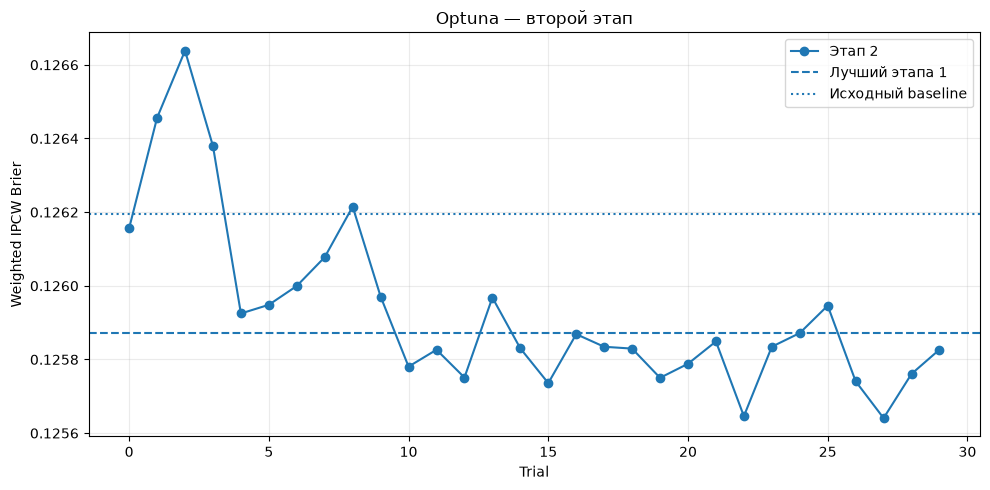

In [6]:
# Можно выполнить отдельно после перезапуска Jupyter, не запуская обучение.
study = optuna.load_study(study_name=STUDY_NAME, storage=STORAGE)
trials_df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
trials_df.to_csv(EXP_DIR / "optuna_trials_stage2.csv", index=False)
completed = trials_df.loc[trials_df.state == "COMPLETE"].sort_values("value")
display(completed.head(15))
fig, ax = plt.subplots(figsize=(10, 5))
if not completed.empty:
    ordered = completed.sort_values("number")
    ax.plot(ordered.number, ordered.value, "o-", label="Этап 2")
ax.axhline(STAGE1_OBJECTIVE, ls="--", label="Лучший этапа 1")
ax.axhline(BASELINE_OBJECTIVE, ls=":", label="Исходный baseline")
ax.set(xlabel="Trial", ylabel="Weighted IPCW Brier", title="Optuna — второй этап")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(EXP_DIR / "optimization_history_stage2.png", dpi=160)
plt.show()


## Выбор модели и сравнение по горизонтам

In [7]:
best_trial = study.best_trial
stage2_path = TRIALS_DIR / f"trial_{best_trial.number:04d}.cbm"
candidates = {
    "baseline": (BASELINE_OBJECTIVE, BASELINE_DIR / "model.cbm"),
    "stage1": (STAGE1_OBJECTIVE, STAGE1_DIR / "best_model.cbm"),
    "stage2": (float(best_trial.value), stage2_path),
}
winner = min(candidates, key=lambda k: candidates[k][0])
winner_score, winner_path = candidates[winner]
shutil.copy2(winner_path, EXP_DIR / "best_model.cbm")
selected_model = CatBoostClassifier()
selected_model.load_model(str(EXP_DIR / "best_model.cbm"))
selected_score, selected_detail = evaluate_cumulative_pd(selected_model, True)
selected_detail.to_csv(EXP_DIR / "best_brier_by_horizon.csv", index=False)

comparison = baseline_detail.rename(columns={"ipcw_brier": "baseline"})
comparison = comparison.merge(
    stage1_detail[["term_months", "horizon_months", "ipcw_brier"]].rename(columns={"ipcw_brier": "stage1"}),
    on=["term_months", "horizon_months"],
).merge(
    selected_detail[["term_months", "horizon_months", "ipcw_brier"]].rename(columns={"ipcw_brier": "selected"}),
    on=["term_months", "horizon_months"],
)
comparison["improvement_vs_baseline"] = comparison["baseline"] - comparison["selected"]
comparison.to_csv(EXP_DIR / "comparison_by_horizon.csv", index=False)
display(comparison)

summary = {
    "winner": winner,
    "stage2_best_trial": int(best_trial.number),
    "stage2_best_value": float(best_trial.value),
    "baseline_weighted_ipcw_brier": float(BASELINE_OBJECTIVE),
    "stage1_weighted_ipcw_brier": float(STAGE1_OBJECTIVE),
    "selected_weighted_ipcw_brier": float(selected_score),
    "stage2_best_params": best_trial.params,
    "stage2_best_iteration": int(best_trial.user_attrs["best_iteration"]),
    "selected_model_source": str(winner_path),
    "horizons_by_term": HORIZONS_BY_TERM,
    "features": MODEL_FEATURES,
    "categorical_features": CAT_FEATURES,
    "test_used": False,
}
with open(EXP_DIR / "best_config.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Победитель:", winner, "weighted Brier:", selected_score)


,term_months,horizon_months,n_episodes,baseline,stage1,selected,improvement_vs_baseline
0,12,6,4775,0.067819,0.068300,0.068544,-0.000725
1,18,6,3864,0.066509,0.066415,0.066497,0.000012
2,18,12,3864,0.113796,0.113969,0.113852,-0.000056
3,24,6,7239,0.069394,0.069270,0.069240,0.000154
4,24,12,7239,0.116971,0.116730,0.116522,0.000449
5,24,18,7239,0.152131,0.151715,0.151352,0.000779
6,36,6,7185,0.073217,0.073507,0.073419,-0.000202
7,36,12,7185,0.124458,0.124320,0.124253,0.000205
8,36,24,7185,0.183440,0.182830,0.182360,0.001080
9,48,6,4196,0.067097,0.067229,0.067205,-0.000108


Победитель: stage2 weighted Brier: 0.12564068424436126


## Калибровка PD по горизонтам

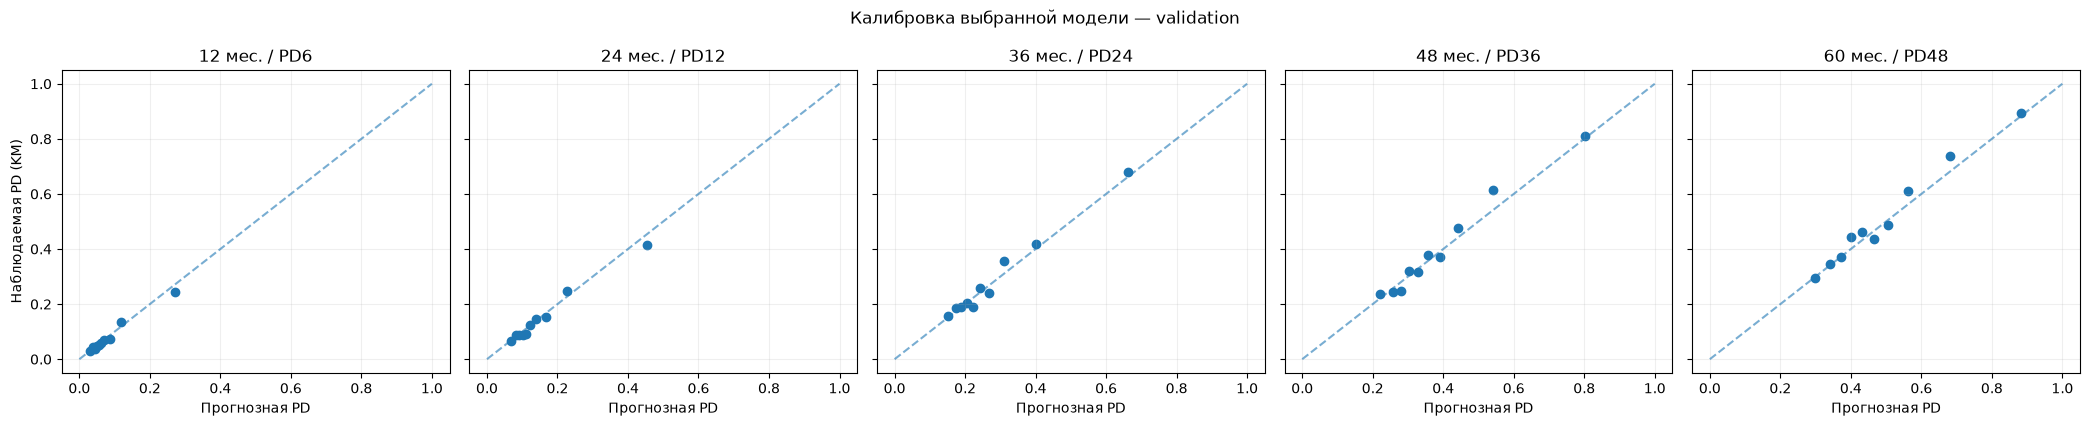

,term_months,horizon_months,weighted_abs_calibration_error,weighted_bias_observed_minus_predicted
0,12,6,0.008039,-0.003943
1,24,12,0.012447,-0.006273
2,36,24,0.017605,0.005678
3,48,36,0.025074,0.008692
4,60,48,0.024624,0.013600


In [8]:
# Наблюдаемая доля дефолтов в бине оценивается по Каплану–Майеру,
# чтобы учитывать правое цензурирование. Используется только validation.
CALIBRATION_PAIRS = [(12, 6), (24, 12), (36, 24), (48, 36), (60, 48)]
N_BINS = 10

def observed_pd_km(episodes, horizon):
    event = episodes["event"].to_numpy(dtype=bool)
    duration = episodes["duration"].to_numpy(dtype=float)
    t, surv = kaplan_meier_estimator(event, duration)
    j = np.searchsorted(t, horizon, side="right") - 1
    return float(1.0 - (surv[j] if j >= 0 else 1.0))

cal_rows = []
fig, axes = plt.subplots(1, len(CALIBRATION_PAIRS), figsize=(21, 4.3), sharex=True, sharey=True)
for ax, (term, horizon) in zip(axes, CALIBRATION_PAIRS):
    g = EVAL_GROUPS[term]
    pred = 1.0 - predict_group_survival(selected_model, term, g)[:, horizon - 1]
    episodes = g["episodes"].copy()
    episodes["pred_pd"] = pred
    episodes["bin"] = pd.qcut(episodes["pred_pd"], q=N_BINS, labels=False, duplicates="drop")
    for bin_id, part in episodes.groupby("bin", sort=True):
        obs = observed_pd_km(part, horizon)
        predicted = float(part["pred_pd"].mean())
        cal_rows.append({
            "term_months": term,
            "horizon_months": horizon,
            "bin": int(bin_id),
            "n_episodes": len(part),
            "predicted_pd": predicted,
            "observed_pd_km": obs,
            "calibration_error": obs - predicted,
        })
    part_rows = [r for r in cal_rows if r["term_months"] == term and r["horizon_months"] == horizon]
    ax.plot([0, 1], [0, 1], "--", alpha=0.6)
    ax.scatter([r["predicted_pd"] for r in part_rows], [r["observed_pd_km"] for r in part_rows])
    ax.set_title(f"{term} мес. / PD{horizon}")
    ax.set_xlabel("Прогнозная PD")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Наблюдаемая PD (KM)")
fig.suptitle("Калибровка выбранной модели — validation")
fig.tight_layout()
fig.savefig(EXP_DIR / "calibration_by_horizon.png", dpi=160)
plt.show()

cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv(EXP_DIR / "calibration_by_horizon.csv", index=False)
cal_summary = cal_df.groupby(["term_months", "horizon_months"]).apply(
    lambda x: pd.Series({
        "weighted_abs_calibration_error": np.average(np.abs(x.calibration_error), weights=x.n_episodes),
        "weighted_bias_observed_minus_predicted": np.average(x.calibration_error, weights=x.n_episodes),
    }),
    include_groups=False,
).reset_index()
cal_summary.to_csv(EXP_DIR / "calibration_summary.csv", index=False)
display(cal_summary)
